In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Изображения успешно загружены.


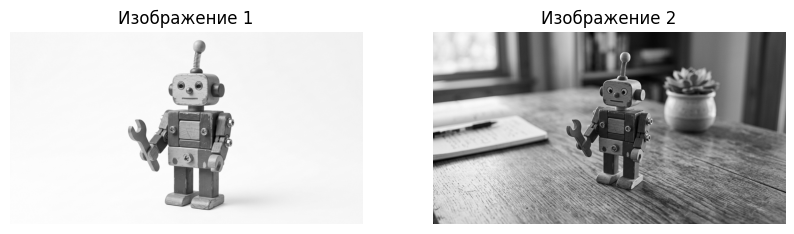

In [2]:
# Загрузка изображений
# img1 - отдельная фотография игрушки (объект)
# img2 - фотография игрушки на фоне стола (сцена)
img1 = cv2.imread('toy.jpg', cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread('toy_on_table.jpg', cv2.IMREAD_GRAYSCALE)

# Проверка, что изображения успешно загрузились
if img1 is None or img2 is None:
    print("Ошибка: Проверьте пути к файлам изображений!")
else:
    print("Изображения успешно загружены.")

plt.figure(figsize=(10,4))
plt.subplot(1,2,1), plt.imshow(img1, cmap='gray'), plt.title("Изображение 1"), plt.axis("off")
plt.subplot(1,2,2), plt.imshow(img2, cmap='gray'), plt.title("Изображение 2"), plt.axis("off")
plt.show()

### Задание 1. Используйте ORB для поиска ключевых точек на фотографии игрушки.

**Ключевые точки (features)** — это устойчивые элементы изображения (углы, контуры, текстурные детали), которые можно надёжно находить даже при изменении масштаба, поворота и освещённости. Для каждой ключевой точки вычисляется **дескриптор** — числовой вектор, описывающий её локальное окружение.

**Использованные методы и параметры:**

1. **ORB_create** — создание детектора ключевых точек
   - `nfeatures=1000` — максимальное количество отбираемых точек (наиболее выразительных по отклику FAST)

2. **detectAndCompute** — одновременный поиск точек и вычисление дескрипторов
   - Возвращает список `KeyPoint` (координаты, размер, ориентация) и матрицу бинарных дескрипторов формы `(N, 32)`

3. **drawKeypoints** — визуализация ключевых точек
   - Флаг: `DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS` — отображает точки с информацией о масштабе (размер круга) и ориентации (направление)

4. **matplotlib (subplot)** — отображение двух изображений рядом для сравнения распределения точек на объекте и на сцене

На изображении 1 найдено точек: 1000
На изображении 2 найдено точек: 1000


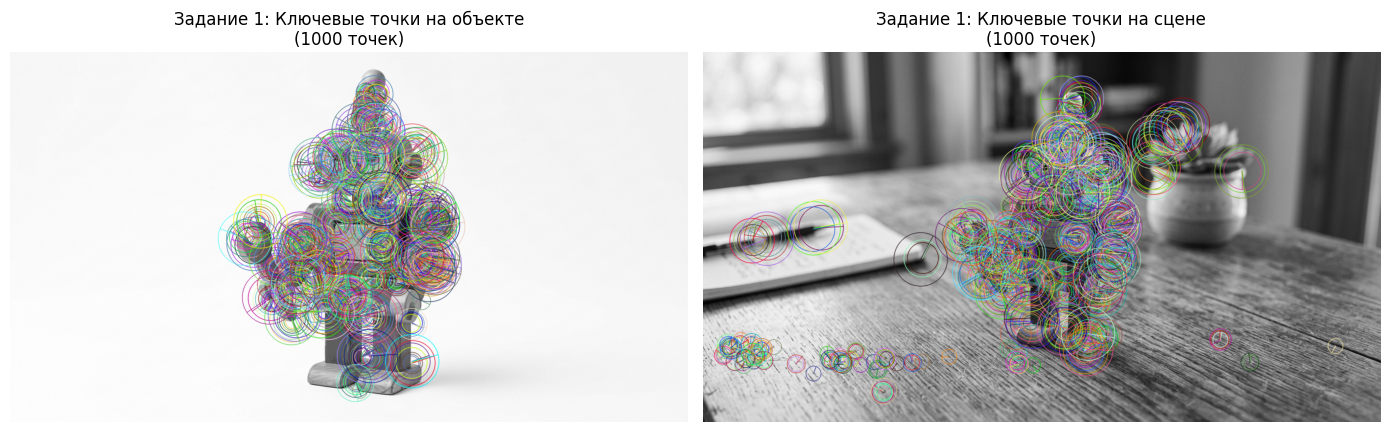

In [3]:
# Создаем детектор ORB
orb = cv2.ORB_create(nfeatures=1000)

# Находим ключевые точки и вычисляем дескрипторы для обоих изображений
kp1, des1 = orb.detectAndCompute(img1, None)
kp2, des2 = orb.detectAndCompute(img2, None)

print(f"На изображении 1 найдено точек: {len(kp1)}")
print(f"На изображении 2 найдено точек: {len(kp2)}")

# Визуализация найденных ключевых точек на 1ом изображении
img1_kp = cv2.drawKeypoints(img1, kp1, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
# Визуализация найденных ключевых точек на 2ом изображении
img2_kp = cv2.drawKeypoints(img2, kp2, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

# Отображение результатов
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img1_kp, cv2.COLOR_BGR2RGB) if len(img1_kp.shape)==3 else img1_kp, cmap='gray')
plt.title(f"Задание 1: Ключевые точки на объекте\n({len(kp1)} точек)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(img2_kp, cv2.COLOR_BGR2RGB) if len(img2_kp.shape)==3 else img2_kp, cmap='gray')
plt.title(f"Задание 1: Ключевые точки на сцене\n({len(kp2)} точек)")
plt.axis('off')

plt.tight_layout()
plt.show()

### Задание 2. Сопоставьте изображение игрушки на фоне стола с её отдельным фото.

**Сопоставление (matching)** — это процесс установления соответствия между ключевыми точками двух изображений на основе сходства их дескрипторов.

**Использованные методы и параметры:**

1. **BFMatcher** — алгоритм полного перебора для сопоставления дескрипторов. Для каждого дескриптора первого изображения он сравнивает его со всеми дескрипторами второго и находит ближайший (с минимальным расстоянием).
   - Метрика: `cv2.NORM_HAMMING` (для бинарных дескрипторов ORB)
   - `crossCheck=False` (требуется для knnMatch)

2. **knnMatch** — поиск k ближайших соседей
   - Параметр: `k=2` (находим лучшее и второе лучшее совпадение)

3. **Фильтр Лоу (Lowe's Ratio Test)** — отсеивание неоднозначных совпадений
   - Порог: `0.75` (лучшее совпадение должно быть на 25% лучше второго)

4. **drawMatches** — визуализация соответствий
   - Показываем: `good_matches[:30]` (первые 30 лучших совпадений)
   - Флаг: `NOT_DRAW_SINGLE_POINTS` (не рисовать точки без пар)

Всего пар: 1000, Хороших совпадений (BF): 17


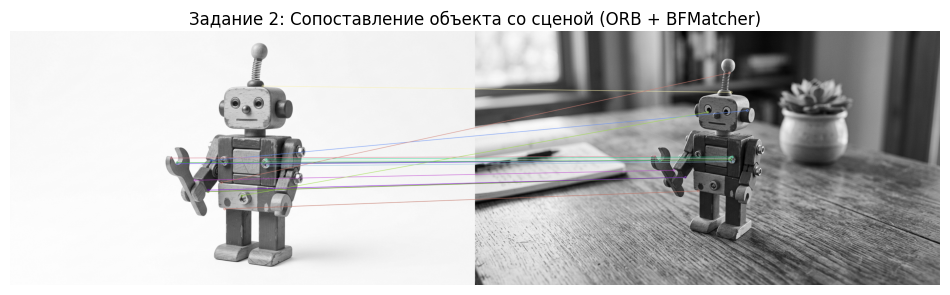

In [4]:
# Создание BFMatcher
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

# Ищем 2 ближайших соседа для каждого дескриптора (для метода Лоу)
matches = bf.knnMatch(des1, des2, k=2)

# Применяем фильтрацию по методу Лоу (порог 0.75)
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print(f"Всего пар: {len(matches)}, Хороших совпадений (BF): {len(good_matches)}")

# Визуализация лучших совпадений
img_matches = cv2.drawMatches(img1, kp1, img2, kp2, good_matches[:30], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# Визуализация результатов
plt.figure(figsize=(12, 6))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB) if len(img_matches.shape)==3 else img_matches, cmap='gray')
plt.title("Задание 2: Сопоставление объекта со сценой (ORB + BFMatcher)")
plt.axis('off')
plt.show()